In [1]:
import  numpy               as np
import  matplotlib.pyplot   as plt
from    GA                  import *

In [3]:
def extinction_time(state0, params, t_max, seed=None):

    rng = np.random.default_rng(seed)
    t, state = 0.0, np.array(state0, dtype=int)

    while t < t_max:
        if state[1] == 0:
            return t
        rates = get_rates(state, params)
        tau, event = first_reaction_step(rates, rng)
        t += tau
        state = state + EVENTS[event]

    return np.inf


def equilibrium(params):

    beta, gamma = params["beta"], params["gamma"]
    mu, N0 = params["mu"], params["N0"]
    R0 = beta / (gamma + mu)
    S = N0 / R0
    I = N0 * mu * (R0 - 1) / beta
    R = N0 - S - I

    return np.array([S, I, R])


def params_from_R0(R0, N0, base):

    beta = R0 * (base["gamma"] + base["mu"])

    return {**base, "beta": beta, "N0": N0}


def extinction_times(R0, N0, base, t_max, n_runs):

    params = params_from_R0(R0, N0, base)
    start = [max(1, round(x)) for x in equilibrium(params)]

    return np.array(
        [extinction_time(start, params, t_max, seed=k)
         for k in range(n_runs)]
    )

In [4]:
base = {"beta": 0.5, "gamma": 0.1, "mu": 0.01, "N0": 1000}
R0_values = [1.25, 1.5, 2, 3, 5, 8]
N0_values = [50, 100, 250, 500, 1000, 2000]
T = 1500
n_runs_ext = 30

ext = {}
for R0 in R0_values:
    for N0 in N0_values:
        ext[(R0, N0)] = extinction_times(R0, N0, base, T, n_runs_ext)

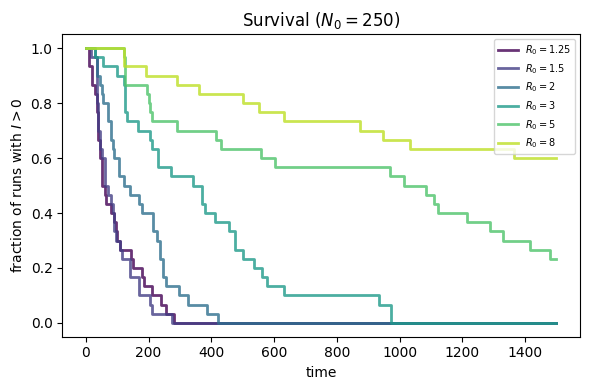

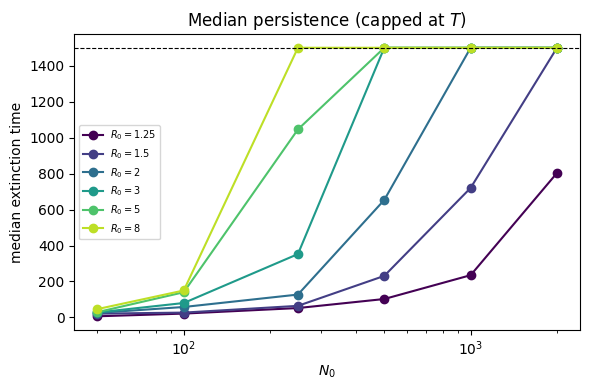

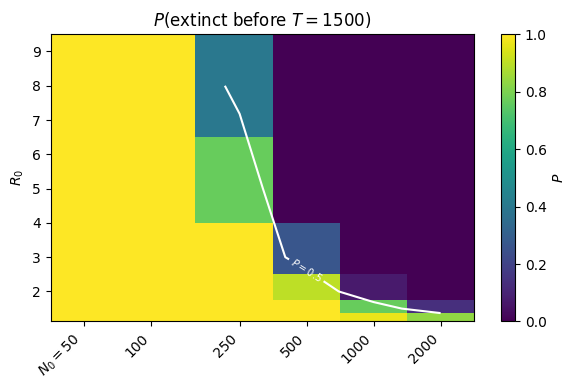

In [5]:
colors = plt.cm.viridis(np.linspace(0, 0.9, len(R0_values)))
t_grid = np.linspace(0, T, 300)
N_ref = 250

# graph 1
fig, ax = plt.subplots(figsize=(6, 4))
for R0, color in zip(R0_values, colors):
    t_ext = ext[(R0, N_ref)]
    survival = (t_ext[None, :] > t_grid[:, None]).mean(axis=1)
    ax.plot(t_grid, survival, color=color, drawstyle="steps-post",
            linewidth=2, alpha=0.8, label=f"$R_0={R0}$")
ax.set_xlabel("time")
ax.set_ylabel("fraction of runs with $I > 0$")
ax.set_title(f"Survival ($N_0={N_ref}$)")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# graph 2
fig, ax = plt.subplots(figsize=(6, 4))
for R0, color in zip(R0_values, colors):
    medians = [np.median(ext[(R0, N0)]) for N0 in N0_values]
    medians = np.minimum(medians, T)
    ax.semilogx(N0_values, medians, "o-", color=color,
                label=f"$R_0={R0}$")
ax.axhline(T, color="k", linestyle="--", linewidth=0.8)
ax.set_xlabel("$N_0$")
ax.set_ylabel("median extinction time")
ax.set_title("Median persistence (capped at $T$)")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# graph 3
logN = np.log10(N0_values)
P = np.array([[np.isfinite(ext[(R0, N0)]).mean() for N0 in N0_values]
              for R0 in R0_values])

fig, ax = plt.subplots(figsize=(6, 4))
mesh = ax.pcolormesh(logN, R0_values, P, shading="nearest",
                     cmap="viridis", vmin=0, vmax=1)
cs = ax.contour(logN, R0_values, P, levels=[0.5], colors="w")
ax.clabel(cs, fmt={0.5: r"$P = 0.5$"}, fontsize=7)

tick_labels = [str(N0) for N0 in N0_values]
tick_labels[0] = rf"$N_0 = {N0_values[0]}$"

ax.set_xticks(logN)
ax.set_xticklabels(tick_labels, rotation=45, ha="right")
ax.set_ylabel("$R_0$")
ax.set_title(f"$P($extinct before $T=${T}$)$")
fig.colorbar(mesh, ax=ax, label=r"$P$")
plt.tight_layout()
plt.show()